# 📩 SMS Spam Detection with Naive Bayes
**Text classification from raw messages: TF-IDF, Bayes' theorem, Laplace smoothing, tuning and error analysis**

**Objective:** Implement and understand the Naive Bayes classifier by detecting spam text messages: turn text into numbers, see exactly how Bayes' theorem produces a prediction, tune the smoothing parameter and judge the model with the right metrics.
**Tools:** Scikit-learn, Pandas, Matplotlib (+ NumPy)
**Dataset:** SMS Spam Collection: 5,572 real text messages labelled *ham* (legitimate) or *spam*

**Pipeline**
1. Load, explore and **de-duplicate** the messages
2. Text signals: message length, digits, capital letters and the most common words
3. How Naive Bayes works, computed by hand and checked against scikit-learn
4. Compare text representations and Naive Bayes variants
5. Smoothing (`alpha`) and a grid search
6. Evaluate: precision, recall, ROC / PR curves and the decision threshold
7. Interpret the model (spam words) and analyse its mistakes
8. Compare with logistic regression and a linear SVM, then predict new messages

In [1]:
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB, ComplementNB, BernoulliNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay)

import warnings
warnings.filterwarnings("ignore")

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_colwidth", 120)
os.makedirs("images", exist_ok=True)   # plots are saved here
RANDOM_STATE = 42
print("✅ Libraries imported")

✅ Libraries imported


## 📥 Step 1: Load & Explore the Messages

In [2]:
def load_sms(path):
    # Handles the common formats of this dataset: spam.csv (v1, v2 | Category, Message) and sms.tsv (label<TAB>message)
    if path.lower().endswith(".tsv"):
        return pd.read_csv(path, sep="\t", header=None, names=["label", "message"])
    raw = pd.read_csv(path, encoding="latin-1")
    raw.columns = [c.strip().lower() for c in raw.columns]
    rename = {"v1": "label", "v2": "message", "category": "label", "text": "message"}
    raw = raw.rename(columns=rename)
    return raw[["label", "message"]]

sms_path = None
for root_dir in ["/kaggle/input", "data"]:
    for dirname, _, filenames in os.walk(root_dir):
        for f in filenames:
            if f.lower().endswith((".csv", ".tsv")):
                try:
                    cand = load_sms(os.path.join(dirname, f))
                except Exception:
                    continue
                if set(cand["label"].astype(str).str.lower().unique()) >= {"ham", "spam"}:
                    sms_path = sms_path or os.path.join(dirname, f)

if sms_path is None:
    raise FileNotFoundError("SMS spam file not found. Add the 'SMS Spam Collection' dataset on Kaggle or put it in data/.")

print("Using file:", sms_path)
df = load_sms(sms_path)
df["label"] = df["label"].str.lower().str.strip()
df = df.dropna().reset_index(drop=True)
print("Shape:", df.shape)
df.sample(6, random_state=1)

Using file: data/spam.csv
Shape: (5572, 2)


,label,message
1078,ham,Convey my regards to him
4028,ham,"[Û_] anyway, many good evenings to u! s"
958,ham,My sort code is and acc no is . The bank is natwest. Can you reply to confirm i've sent this to the right person!
4642,ham,Sorry i din lock my keypad.
4674,spam,"Hi babe its Chloe, how r u? I was smashed on saturday night, it was great! How was your weekend? U been missing me? ..."
5461,ham,Ok i thk i got it. Then u wan me 2 come now or wat?


       count     %
label             
ham     4825  86.6
spam     747  13.4

Duplicate messages: 403  |  messages that appear with BOTH labels: 0


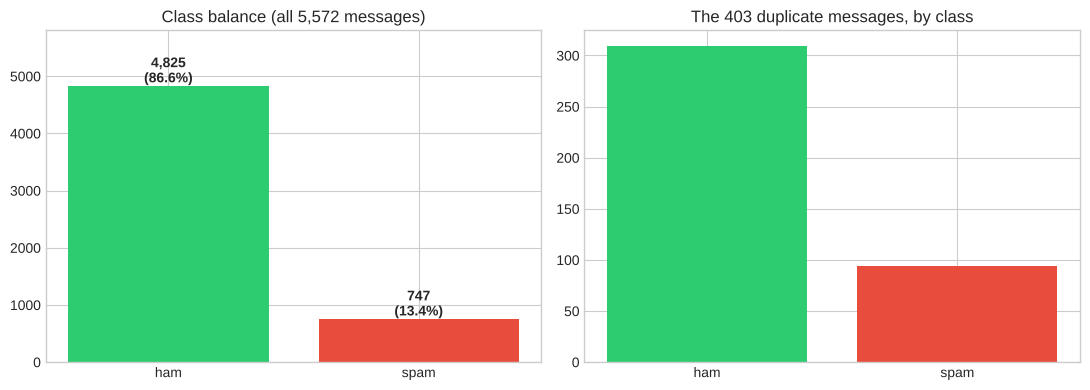

In [3]:
counts = df["label"].value_counts()
print(pd.DataFrame({"count": counts, "%": (counts / len(df) * 100).round(1)}))

n_dup = int(df["message"].duplicated().sum())
conflicts = int((df.groupby("message")["label"].nunique() > 1).sum())
print(f"\nDuplicate messages: {n_dup}  |  messages that appear with BOTH labels: {conflicts}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(counts.index, counts.values, color=["#2ecc71", "#e74c3c"])
for i, v in enumerate(counts.values):
    axes[0].text(i, v, f"{v:,}\n({v / len(df) * 100:.1f}%)", ha="center", va="bottom", fontweight="bold")
axes[0].set_ylim(0, 5800); axes[0].set_title("Class balance (all 5,572 messages)")

dup_by_class = df[df["message"].duplicated(keep="first")]["label"].value_counts()
axes[1].bar(dup_by_class.index, dup_by_class.values, color=["#2ecc71", "#e74c3c"])
axes[1].set_title(f"The {n_dup} duplicate messages, by class")
plt.tight_layout()
plt.savefig("images/01_class_balance_and_duplicates.png", dpi=150, bbox_inches="tight")
plt.show()

### 📝 Observations
- **5,572 messages:** 4,825 ham (86.6%) and 747 spam (13.4%): an **imbalanced** problem, so plain accuracy is misleading (always answering "ham" is already 86.6% accurate)
- **403 messages are exact duplicates** (spammers re-send the same text). If duplicates end up in both the training and the test set, the model is partly graded on messages it has already seen, which inflates the score (a **data-leakage** trap)
- No message appears with both labels, so removing duplicates is safe

In [4]:
# Remove duplicates BEFORE splitting, so no test message is also a training message
before = df.copy()
df = df.drop_duplicates(subset="message").reset_index(drop=True)
y = (df["label"] == "spam").astype(int)
X = df["message"]
print(f"After de-duplication: {len(df):,} unique messages | spam share = {y.mean():.1%}  ({y.sum()} spam, {len(y) - y.sum():,} ham)")

# How bad would the leakage have been? Split WITHOUT de-duplicating and count the overlap.
yb = (before["label"] == "spam").astype(int)
Xa, Xb, _, _ = train_test_split(before["message"], yb, test_size=0.2, random_state=RANDOM_STATE, stratify=yb)
print(f"Without de-duplication: {int(Xb.isin(set(Xa)).sum())} of {len(Xb):,} test messages also appear in the training set")

After de-duplication: 5,169 unique messages | spam share = 12.6%  (653 spam, 4,516 ham)
Without de-duplication: 129 of 1,115 test messages also appear in the training set


## 🔎 Step 2: What Does Spam Look Like?

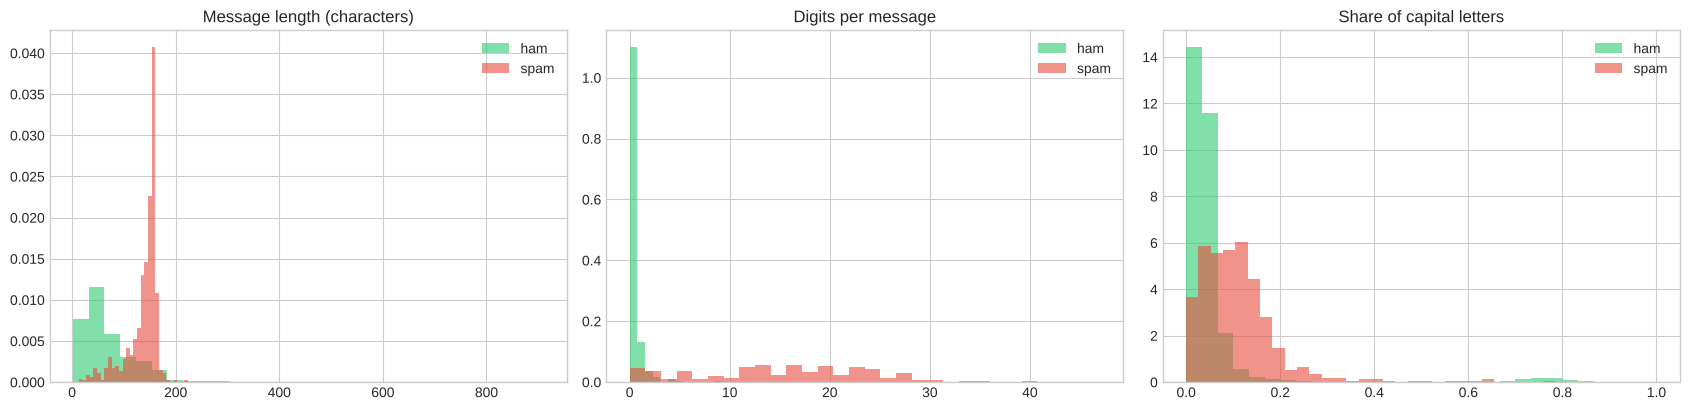

        length  digits  caps_ratio
label                             
ham     70.459   0.290       0.057
spam   137.891  15.447       0.110


In [5]:
feat = pd.DataFrame({
    "label": df["label"],
    "length": df["message"].str.len(),
    "digits": df["message"].str.count(r"\d"),
    "caps_ratio": df["message"].str.count(r"[A-Z]") / df["message"].str.len(),
})

fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
for ax, col, title in zip(axes, ["length", "digits", "caps_ratio"],
                          ["Message length (characters)", "Digits per message", "Share of capital letters"]):
    for label, color in [("ham", "#2ecc71"), ("spam", "#e74c3c")]:
        ax.hist(feat.loc[feat["label"] == label, col], bins=30, alpha=0.6, color=color, label=label, density=True)
    ax.set_title(title); ax.legend()
plt.tight_layout()
plt.savefig("images/02_message_signals.png", dpi=150, bbox_inches="tight")
plt.show()

print(feat.groupby("label")[["length", "digits", "caps_ratio"]].mean().round(3))

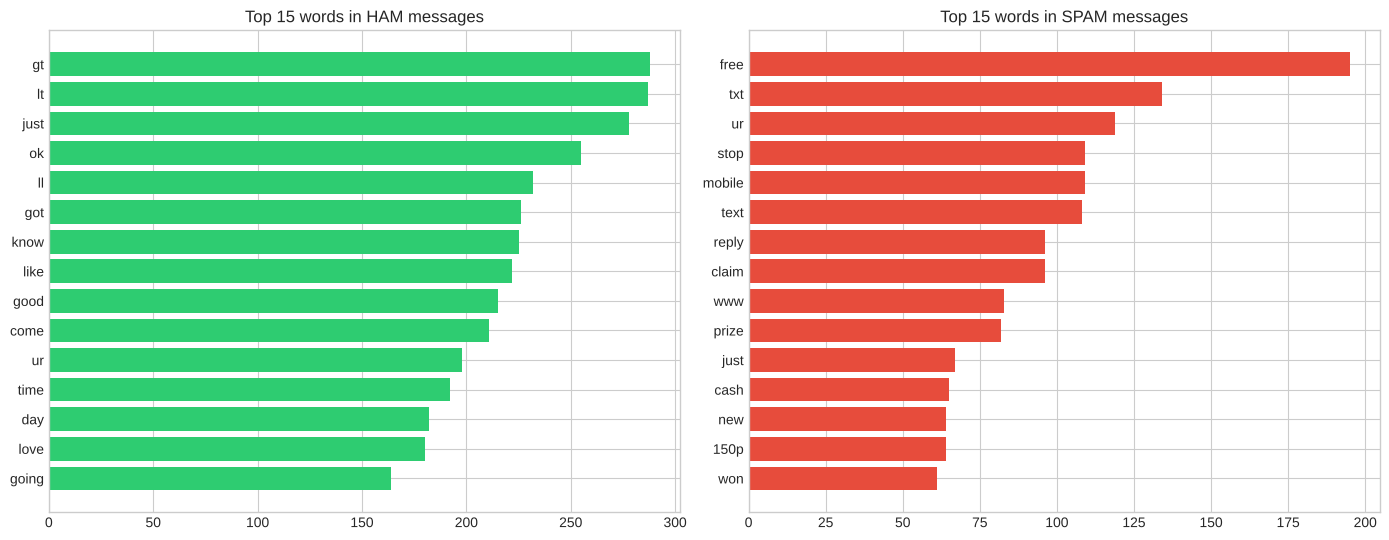

In [6]:
# Most frequent words per class (English stop words removed)
cv_words = CountVectorizer(stop_words="english", min_df=2)
counts_mat = cv_words.fit_transform(X)
vocab = np.array(cv_words.get_feature_names_out())

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, (label, color) in zip(axes, [("ham", "#2ecc71"), ("spam", "#e74c3c")]):
    word_counts = np.asarray(counts_mat[(df["label"] == label).values].sum(axis=0)).ravel()
    top = np.argsort(word_counts)[-15:]
    ax.barh(vocab[top], word_counts[top], color=color)
    ax.set_title(f"Top 15 words in {label.upper()} messages")
plt.tight_layout()
plt.savefig("images/03_top_words_per_class.png", dpi=150, bbox_inches="tight")
plt.show()

### 📝 Observations
- Spam messages are **twice as long** (mean ≈ 138 vs 70 characters) and packed with **digits** (≈ 15.4 per message vs 0.3: phone numbers, prices, short codes)
- They also use more **capital letters** (11% vs 6%)
- Ham is dominated by everyday chat words; spam by calls to action ("free", "call", "txt", "claim", "mobile", "prize", "reply")
- Words alone already separate the classes well, which is exactly what Naive Bayes exploits

## ✂️ Step 3: Split the Data

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
print("Train:", len(X_train), "| Test:", len(X_test))
print(f"Spam share  train: {y_train.mean():.3f}  |  test: {y_test.mean():.3f}")
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

Train: 4135 | Test: 1034
Spam share  train: 0.126  |  test: 0.127


## 🧮 Step 4: How Naive Bayes Works (computed by hand)
For a message made of words w₁ … wₙ, **Bayes' theorem** gives the probability that it is spam:

**P(spam | words) ∝ P(spam) × P(w₁ | spam) × P(w₂ | spam) × … × P(wₙ | spam)**

- **P(spam)** is the *prior*: how common spam is overall
- **P(wᵢ | spam)** is how often word wᵢ appears in spam messages
- The **"naive"** part: it assumes words are *independent* given the class (not true in language, but it works surprisingly well)
- **Laplace smoothing** (`alpha`) adds a small count to every word, so a word never seen in spam does not force the probability to exactly 0
- Everything is computed with **logarithms** (sums instead of products) to avoid numerical underflow

We compute this manually for one real message and check that scikit-learn agrees.

In [8]:
vec = CountVectorizer()
Xc_train = vec.fit_transform(X_train)
nb = MultinomialNB(alpha=1.0).fit(Xc_train, y_train)

# pick a short spam message from the test set that the model gets right
spam_msgs = X_test[(y_test == 1) & (X_test.str.len() < 120)]
msg = next(m for m in spam_msgs if nb.predict(vec.transform([m]))[0] == 1)
x = vec.transform([msg])
print("Message:", msg, "\n")

log_prior_spam, log_prior_ham = nb.class_log_prior_[1], nb.class_log_prior_[0]
idx = x.nonzero()[1]
words = vec.get_feature_names_out()[idx]
llr = nb.feature_log_prob_[1][idx] - nb.feature_log_prob_[0][idx]      # log P(w|spam) - log P(w|ham)
table = pd.DataFrame({"word": words, "count": np.asarray(x[0, idx].todense()).ravel(), "log-ratio spam/ham": llr.round(2)})
display(table.sort_values("log-ratio spam/ham", ascending=False).reset_index(drop=True))

log_spam = log_prior_spam + x.dot(nb.feature_log_prob_[1]).item()
log_ham = log_prior_ham + x.dot(nb.feature_log_prob_[0]).item()
p_manual = 1 / (1 + np.exp(log_ham - log_spam))

print(f"prior: P(spam) = {np.exp(log_prior_spam):.3f}, P(ham) = {np.exp(log_prior_ham):.3f}")
print(f"log-score spam = {log_spam:.2f}   |   log-score ham = {log_ham:.2f}")
print(f"P(spam | message), by hand      : {p_manual:.6f}")
print(f"P(spam | message), scikit-learn : {nb.predict_proba(x)[0, 1]:.6f}")
print("Identical:", np.isclose(p_manual, nb.predict_proba(x)[0, 1]))

Message: Your unique user ID is 1172. For removal send STOP to 87239 customer services 08708034412 



,word,count,log-ratio spam/ham
0,services,1,2.95
1,87239,1,2.39
2,customer,1,2.33
3,user,1,2.26
4,stop,1,2.07
5,08708034412,1,1.70
6,removal,1,1.70
7,unique,1,1.01
8,your,1,0.51
9,send,1,0.50


prior: P(spam) = 0.126, P(ham) = 0.874
log-score spam = -98.28   |   log-score ham = -112.89
P(spam | message), by hand      : 1.000000
P(spam | message), scikit-learn : 1.000000
Identical: True


### 📝 Observations
- Each word contributes a **log-ratio**: positive pushes toward spam, negative toward ham. The message score is simply the **prior plus the sum of these evidence terms**
- The hand-computed probability **matches scikit-learn exactly**: Naive Bayes is nothing more than counting words and adding logarithms. It has **no iterative training**, which is why it is so fast

## 📊 Step 5: Text Representations & Naive Bayes Variants
- **Bag of Words (CountVectorizer):** word counts
- **TF-IDF:** counts re-weighted so that words common to all messages count less, and rows are normalised to length 1
- **MultinomialNB** (counts / TF-IDF), **ComplementNB** (designed for imbalanced text), **BernoulliNB** (word present / absent)

The main metrics are for the **spam class**: precision (of messages flagged as spam, how many are?), recall (of all spam, how much did we catch?) and F1.

,CV F1,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,,
BoW + MultinomialNB,0.935,0.986,0.976,0.916,0.945,0.982
BoW (stop words) + MultinomialNB,0.933,0.985,0.960,0.916,0.938,0.984
TF-IDF + MultinomialNB,0.763,0.952,1.000,0.618,0.764,0.986
TF-IDF + ComplementNB,0.900,0.975,0.913,0.885,0.899,0.986
Binary BoW + BernoulliNB,0.861,0.976,0.991,0.817,0.895,0.997


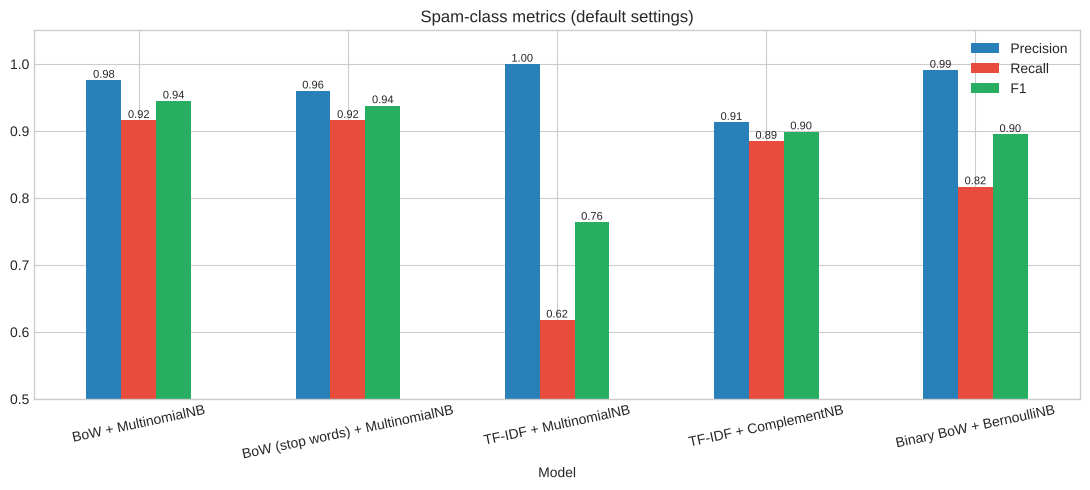

In [9]:
candidates = {
    "BoW + MultinomialNB":              make_pipeline(CountVectorizer(), MultinomialNB()),
    "BoW (stop words) + MultinomialNB": make_pipeline(CountVectorizer(stop_words="english"), MultinomialNB()),
    "TF-IDF + MultinomialNB":           make_pipeline(TfidfVectorizer(), MultinomialNB()),
    "TF-IDF + ComplementNB":            make_pipeline(TfidfVectorizer(), ComplementNB()),
    "Binary BoW + BernoulliNB":         make_pipeline(CountVectorizer(binary=True), BernoulliNB()),
}
rows = []
for name, pipe in candidates.items():
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    rows.append({"Model": name,
                 "CV F1": cross_val_score(pipe, X_train, y_train, cv=cv, scoring="f1").mean(),
                 "Accuracy": accuracy_score(y_test, pred), "Precision": precision_score(y_test, pred),
                 "Recall": recall_score(y_test, pred), "F1": f1_score(y_test, pred),
                 "ROC-AUC": roc_auc_score(y_test, pipe.predict_proba(X_test)[:, 1])})
compare = pd.DataFrame(rows).set_index("Model").round(3)
display(compare)

ax = compare[["Precision", "Recall", "F1"]].plot(kind="bar", figsize=(11, 5), color=["#2980b9", "#e74c3c", "#27ae60"], rot=12)
ax.set_ylim(0.5, 1.05); ax.set_title("Spam-class metrics (default settings)")
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f", fontsize=8)
plt.tight_layout()
plt.savefig("images/04_variant_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

### 📝 Observations (default settings)
| Model | Precision | Recall | F1 |
|---|---|---|---|
| BoW + MultinomialNB | 0.976 | 0.916 | **0.945** |
| BoW (stop words) + MultinomialNB | 0.960 | 0.916 | 0.938 |
| TF-IDF + MultinomialNB | **1.000** | **0.618** | 0.764 |
| TF-IDF + ComplementNB | 0.913 | 0.885 | 0.899 |
| Binary BoW + BernoulliNB | 0.991 | 0.817 | 0.895 |

- Plain **bag of words works best out of the box**. **TF-IDF with default settings is surprisingly poor**: perfect precision (no false alarms) but it **misses 38% of spam** (recall 0.618)
- Why? TF-IDF rows are normalised, so every feature value is **tiny** (well below 1), and the default smoothing `alpha = 1` is huge *relative to those values*: it flattens the differences between words. The next step shows that **`alpha` must be tuned to the scale of the features**
- Every variant has a ROC-AUC ≥ 0.98, so the ranking ability is fine: the problem is the default decision rule, not the information in the words

## 🎚️ Step 6: Smoothing (`alpha`) Matters
Small `alpha` trusts the observed word counts, large `alpha` pulls all words toward equal probability (more smoothing). We sweep it for both representations.

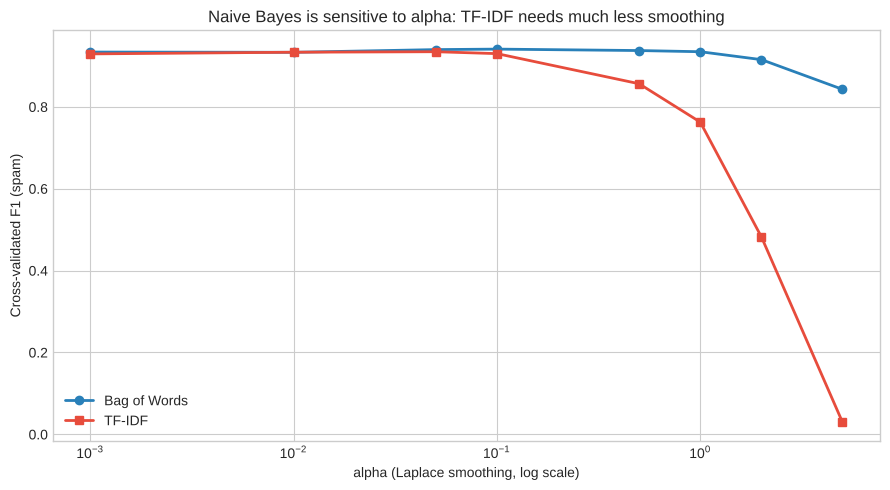

,Bag of Words,TF-IDF
alpha,,
0.001,0.934,0.929
0.010,0.933,0.933
0.050,0.940,0.935
0.100,0.941,0.930
0.500,0.937,0.856
1.000,0.935,0.763
2.000,0.915,0.482
5.000,0.843,0.030


In [10]:
alphas = [0.001, 0.01, 0.05, 0.1, 0.5, 1, 2, 5]
sweep = {}
for name, make_vec in [("Bag of Words", CountVectorizer), ("TF-IDF", TfidfVectorizer)]:
    sweep[name] = [cross_val_score(make_pipeline(make_vec(), MultinomialNB(alpha=a)), X_train, y_train, cv=cv, scoring="f1").mean()
                   for a in alphas]

plt.figure(figsize=(9, 5))
plt.semilogx(alphas, sweep["Bag of Words"], "o-", color="#2980b9", linewidth=2, label="Bag of Words")
plt.semilogx(alphas, sweep["TF-IDF"], "s-", color="#e74c3c", linewidth=2, label="TF-IDF")
plt.xlabel("alpha (Laplace smoothing, log scale)"); plt.ylabel("Cross-validated F1 (spam)")
plt.title("Naive Bayes is sensitive to alpha: TF-IDF needs much less smoothing")
plt.legend()
plt.tight_layout()
plt.savefig("images/05_alpha_sweep.png", dpi=150, bbox_inches="tight")
plt.show()

display(pd.DataFrame(sweep, index=alphas).rename_axis("alpha").round(3))

### 📝 Observations (alpha)
- **Bag of Words** is forgiving: its cross-validated F1 stays between **0.933 and 0.941** for every `alpha` from 0.001 to 1 (best at 0.1), and only drops when `alpha` reaches 2 to 5
- **TF-IDF** is far more sensitive. It is best at small values (**0.935 at `alpha = 0.05`**) and then **collapses**: 0.856 at 0.5, 0.763 at 1 (the default), 0.482 at 2 and **0.030 at 5** (almost everything is called ham)
- Lesson: `alpha` is a hyper-parameter that must be tuned together with the feature representation, never left at the default

## 🔧 Step 7: Grid Search (representation + smoothing, scored on F1)
Search 80 combinations of n-grams (single words vs word pairs), minimum document frequency, stop words, sublinear term frequency and `alpha`, using 5-fold cross-validation **on the training data only**.

In [11]:
pipe = Pipeline([("vec", TfidfVectorizer()), ("nb", MultinomialNB())])
param_grid = {
    "vec__ngram_range": [(1, 1), (1, 2)],
    "vec__min_df": [1, 2],
    "vec__stop_words": [None, "english"],
    "vec__sublinear_tf": [False, True],
    "nb__alpha": [0.01, 0.05, 0.1, 0.5, 1],
}
grid = GridSearchCV(pipe, param_grid, cv=cv, scoring="f1", n_jobs=-1).fit(X_train, y_train)
best = grid.best_estimator_

print("Combinations tried:", len(grid.cv_results_["params"]))
print("Best parameters   :", {k.split("__")[1]: v for k, v in grid.best_params_.items()})
print(f"Best CV F1        : {grid.best_score_:.4f}")
print("Vocabulary size   :", len(best.named_steps["vec"].get_feature_names_out()))

Combinations tried: 80
Best parameters   : {'alpha': 0.01, 'min_df': 1, 'ngram_range': (1, 2), 'stop_words': 'english', 'sublinear_tf': False}
Best CV F1        : 0.9420
Vocabulary size   : 30960


### 📝 Observations (tuning)
- Best: **TF-IDF with word pairs (1 to 2-grams), English stop words removed, `alpha = 0.01`**, `min_df = 1`, no sublinear scaling: CV F1 **0.9420**, up from 0.763 for the default TF-IDF model (vocabulary of 30,960 terms)
- **Word pairs** help: phrases such as *"to claim"* or *"have won"* are stronger spam signals than the single words
- A tiny `alpha` works because TF-IDF features are small numbers

## 🎯 Step 8: Evaluate the Tuned Model on the Test Set

Accuracy : 0.9855
Precision: 0.9603   (of messages flagged as spam, how many really are)
Recall   : 0.9237   (of all spam, how much we caught)
F1       : 0.9416
ROC-AUC  : 0.9909   |   PR-AUC: 0.9745

              precision    recall  f1-score   support

         ham      0.989     0.994     0.992       903
        spam      0.960     0.924     0.942       131

    accuracy                          0.985      1034
   macro avg      0.975     0.959     0.967      1034
weighted avg      0.985     0.985     0.985      1034



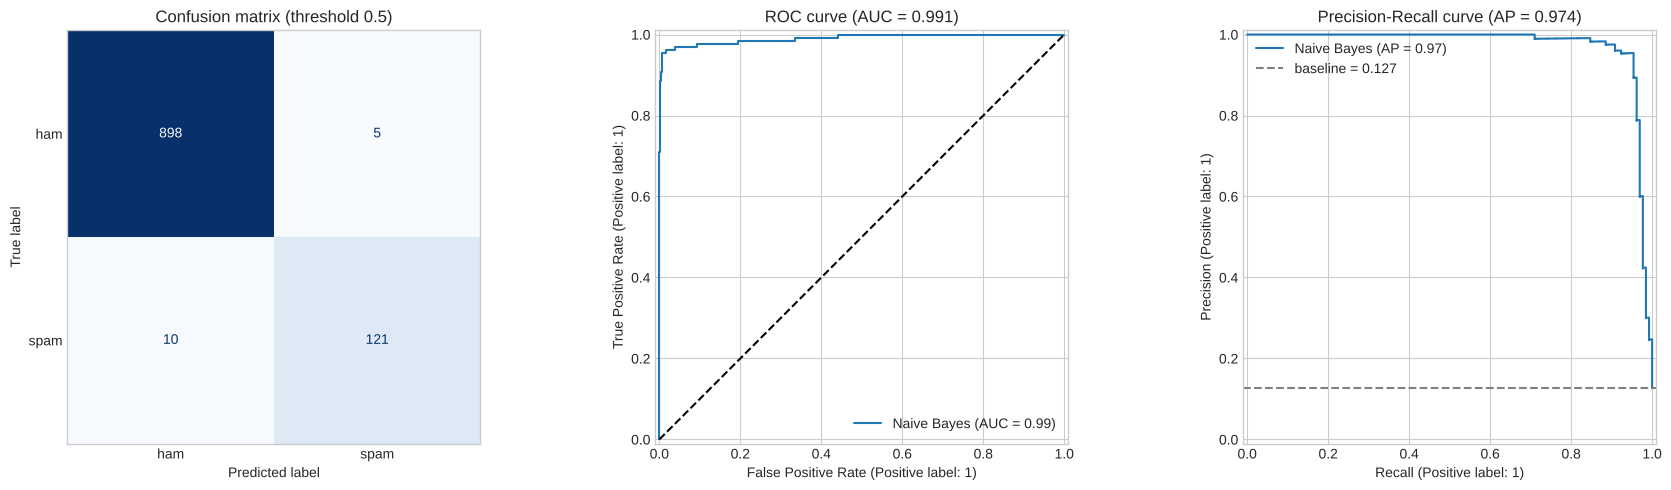

In [12]:
pred = best.predict(X_test)
prob = best.predict_proba(X_test)[:, 1]

print(f"Accuracy : {accuracy_score(y_test, pred):.4f}")
print(f"Precision: {precision_score(y_test, pred):.4f}   (of messages flagged as spam, how many really are)")
print(f"Recall   : {recall_score(y_test, pred):.4f}   (of all spam, how much we caught)")
print(f"F1       : {f1_score(y_test, pred):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_test, prob):.4f}   |   PR-AUC: {average_precision_score(y_test, prob):.4f}\n")
print(classification_report(y_test, pred, target_names=["ham", "spam"], digits=3))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["ham", "spam"], cmap="Blues", ax=axes[0], colorbar=False)
axes[0].set_title("Confusion matrix (threshold 0.5)"); axes[0].grid(False)
RocCurveDisplay.from_predictions(y_test, prob, ax=axes[1], name="Naive Bayes")
axes[1].plot([0, 1], [0, 1], "k--"); axes[1].set_title(f"ROC curve (AUC = {roc_auc_score(y_test, prob):.3f})")
PrecisionRecallDisplay.from_predictions(y_test, prob, ax=axes[2], name="Naive Bayes")
axes[2].axhline(y_test.mean(), color="gray", linestyle="--", label=f"baseline = {y_test.mean():.3f}"); axes[2].legend()
axes[2].set_title(f"Precision-Recall curve (AP = {average_precision_score(y_test, prob):.3f})")
plt.tight_layout()
plt.savefig("images/06_evaluation_curves.png", dpi=150, bbox_inches="tight")
plt.show()

### 📝 Observations (test performance)
- **Accuracy 0.9855**, **precision 0.960**, **recall 0.924**, **F1 0.942**, **ROC-AUC 0.991**
- Confusion matrix: **898 ham correct, 5 ham wrongly flagged as spam, 10 spam missed, 121 spam caught** (1,034 test messages)
- Compared with the always-"ham" baseline (accuracy 87.3% and **zero** spam caught), the model catches 121 of 131 spam messages

## ⚖️ Step 9: The Decision Threshold: Which Mistake Costs More?
Wrongly sending a **real message to the spam folder** (false positive) is usually worse than letting one spam through (false negative).
So we can raise the threshold: only flag a message when the model is very sure.

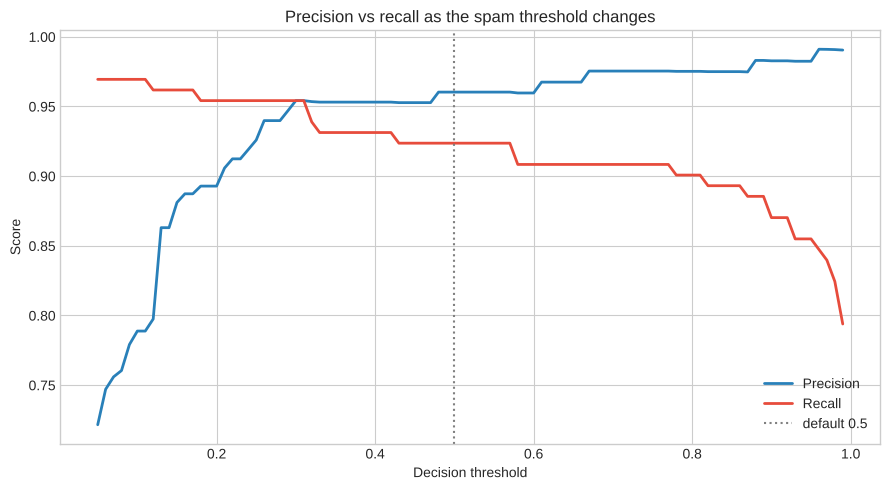

,Precision,Recall,Ham wrongly flagged (FP),Spam missed (FN)
Threshold,,,,
0.30,0.954,0.954,6,6
0.50,0.960,0.924,5,10
0.70,0.975,0.908,3,12
0.90,0.983,0.870,2,17
0.95,0.982,0.855,2,19


In [13]:
thresholds = np.linspace(0.05, 0.99, 95)
prec = [precision_score(y_test, (prob >= t).astype(int), zero_division=1) for t in thresholds]
rec = [recall_score(y_test, (prob >= t).astype(int)) for t in thresholds]

plt.figure(figsize=(9, 5))
plt.plot(thresholds, prec, label="Precision", color="#2980b9", linewidth=2)
plt.plot(thresholds, rec, label="Recall", color="#e74c3c", linewidth=2)
plt.axvline(0.5, color="gray", linestyle=":", label="default 0.5")
plt.xlabel("Decision threshold"); plt.ylabel("Score")
plt.title("Precision vs recall as the spam threshold changes")
plt.legend()
plt.tight_layout()
plt.savefig("images/07_threshold_tradeoff.png", dpi=150, bbox_inches="tight")
plt.show()

rows = []
for t in [0.3, 0.5, 0.7, 0.9, 0.95]:
    q = (prob >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, q).ravel()
    rows.append({"Threshold": t, "Precision": precision_score(y_test, q), "Recall": recall_score(y_test, q),
                 "Ham wrongly flagged (FP)": fp, "Spam missed (FN)": fn})
pd.DataFrame(rows).round(3).set_index("Threshold")

### 📝 Observations (threshold)
| Threshold | Precision | Recall | Ham flagged as spam | Spam missed |
|---|---|---|---|---|
| 0.3 | 0.954 | 0.954 | 6 | 6 |
| 0.5 (default) | 0.960 | 0.924 | 5 | 10 |
| 0.7 | 0.975 | 0.908 | 3 | 12 |
| 0.9 | 0.983 | 0.870 | 2 | 17 |
| 0.95 | 0.982 | 0.855 | 2 | 19 |

Raising the threshold trades **recall for precision**: from 0.5 to 0.9 the false alarms fall from 5 to 2, but missed spam climbs from 10 to 17.
Lowering it to 0.3 gives the most **balanced** result (6 false alarms, 6 missed). No threshold reaches zero false alarms, because a couple of ordinary messages (e.g. *"Nokia phone is lovly.."*) get a spam probability close to 1.
A mail provider would pick the value from the cost of each mistake type.

## 🔍 Step 10: Which Words Does the Model Trust?

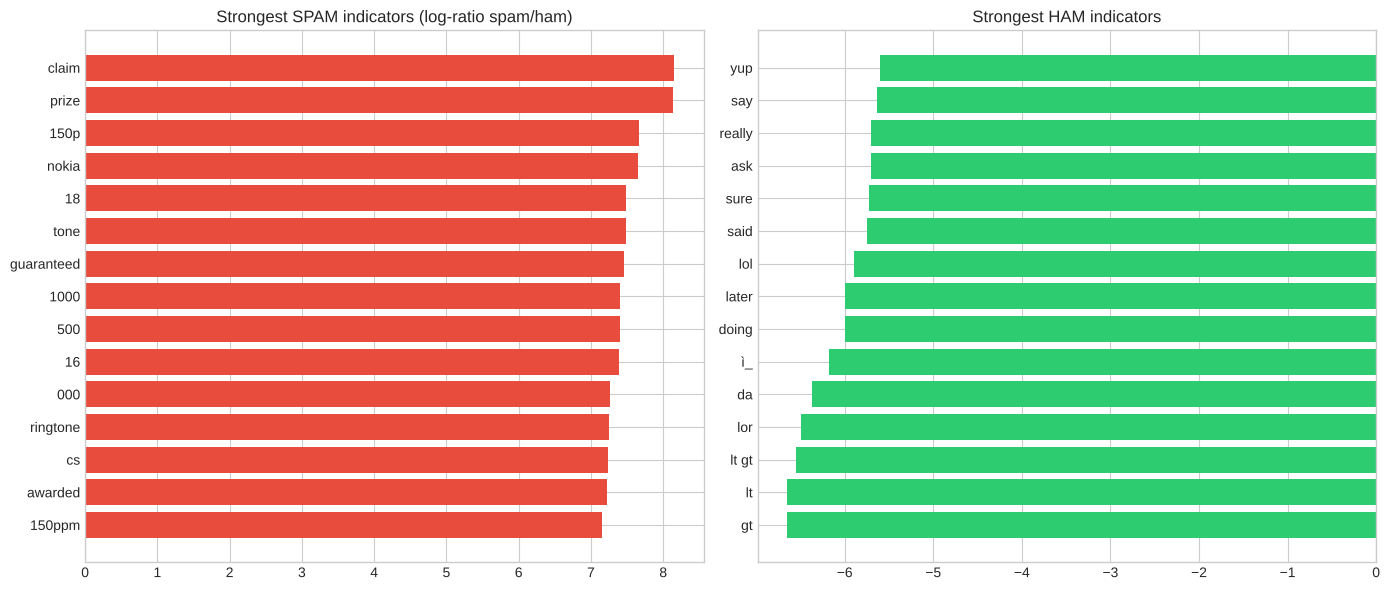

Top spam terms: ['claim', 'prize', '150p', 'nokia', '18', 'tone', 'guaranteed', '1000', '500', '16', '000', 'ringtone']
Top ham terms : ['gt', 'lt', 'lt gt', 'lor', 'da', 'ì_', 'doing', 'later', 'lol', 'said', 'sure', 'ask']


In [14]:
vec_b, nb_b = best.named_steps["vec"], best.named_steps["nb"]
terms = np.array(vec_b.get_feature_names_out())
log_ratio = nb_b.feature_log_prob_[1] - nb_b.feature_log_prob_[0]
order = np.argsort(log_ratio)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
spam_idx, ham_idx = order[-15:], order[:15]
axes[0].barh(terms[spam_idx], log_ratio[spam_idx], color="#e74c3c"); axes[0].set_title("Strongest SPAM indicators (log-ratio spam/ham)")
axes[1].barh(terms[ham_idx], log_ratio[ham_idx], color="#2ecc71"); axes[1].set_title("Strongest HAM indicators")
plt.tight_layout()
plt.savefig("images/08_spam_and_ham_words.png", dpi=150, bbox_inches="tight")
plt.show()

print("Top spam terms:", list(terms[spam_idx][::-1][:12]))
print("Top ham terms :", list(terms[ham_idx][:12]))

### 📝 Observations (interpretation)
Naive Bayes is **fully interpretable**: each word or word pair has a spam/ham log-ratio. The strongest spam indicators are *claim, prize, 150p, nokia, 18, tone, guaranteed, 1000, 500, ringtone*: prices, ages (18) and short codes, plus phone-offer vocabulary.
The strongest ham indicators are chatty words and abbreviations (*lor, da, doing, later, lol, said, sure, ask*), `gt` / `lt` / `lt gt` (leftovers of "&gt;" / "&lt;" in the data) and `ì_` (an encoding leftover): a reminder that a model learns *patterns in the data*, including quirks and artefacts.
Note that *nokia* is a spam indicator, so a genuine message such as *"Nokia phone is lovly.."* is wrongly flagged: a classic Naive Bayes side-effect of judging each word on its own.

## 🕵️ Step 11: Error Analysis: What Does the Model Get Wrong?

In [15]:
errors = pd.DataFrame({"message": X_test.values, "true": np.where(y_test.values == 1, "spam", "ham"),
                       "P(spam)": prob.round(2)})
errors = errors[pred != y_test.values].sort_values("P(spam)")
print(f"{len(errors)} mistakes out of {len(X_test)} test messages\n")
display(errors.reset_index(drop=True))

15 mistakes out of 1034 test messages



,message,true,P(spam)
0,Babe: U want me dont u baby! Im nasty and have a thing 4 filthyguys. Fancy a rude time with a sexy bitch. How about ...,spam,0.00
1,"Xmas & New Years Eve tickets are now on sale from the club, during the day from 10am till 8pm, and on Thurs, Fri & S...",spam,0.00
2,"In The Simpsons Movie released in July 2007 name the band that died at the start of the film? A-Green Day, B-Blue Da...",spam,0.00
3,Missed call alert. These numbers called but left no message. 07008009200,spam,0.01
4,Burger King - Wanna play footy at a top stadium? Get 2 Burger King before 1st Sept and go Large or Super with Coca-C...,spam,0.11
5,Check Out Choose Your Babe Videos @ sms.shsex.netUN fgkslpoPW fgkslpo,spam,0.18
6,Thanks for the Vote. Now sing along with the stars with Karaoke on your mobile. For a FREE link just reply with SING...,spam,0.31
7,Hi if ur lookin 4 saucy daytime fun wiv busty married woman Am free all next week Chat now 2 sort time 09099726429 J...,spam,0.32
8,"Latest News! Police station toilet stolen, cops have nothing to go on!",spam,0.32
9,ASKED 3MOBILE IF 0870 CHATLINES INCLU IN FREE MINS. INDIA CUST SERVs SED YES. L8ER GOT MEGA BILL. 3 DONT GIV A SHIT....,spam,0.42


### 📝 Observations (errors)
- **Missed spam (10):** the model is blind to spam that does not use the usual vocabulary: **adult chat-line and dating ads** (*"Hi if ur lookin 4 saucy daytime fun..."*, *"Check Out Choose Your Babe Videos @ sms.shsex.net..."*), **promotions** (Burger King, Xmas tickets, a karaoke vote), a **quiz / news service** (*"In The Simpsons Movie released in July 2007 name the band..."*, *"Latest News! Police station toilet stolen..."*), a **missed-call alert** that is just a phone number, and a text about 3Mobile chat lines
- **False alarms (5):** short slang texts that happen to contain spam-flavoured tokens: *"YO YO YO BYATCH WHASSUP?"* (0.61), *"K k:) sms chat with me."* (0.66), *"U WILL SWITCH YOUR FONE ON DAMMIT!!"* (0.88), *"K:)eng rocking in ashes:)"* (0.95) and *"Nokia phone is lovly.."* (1.00). Capitals, "sms", "fone" and "nokia" are all more common in spam than in ham
- Fixing these needs more than word counts: URL / phone-number patterns as features, character n-grams, sender information or context-aware language models

## ⚖️ Step 12: Compare with Other Text Classifiers (same TF-IDF features)

,Precision,Recall,F1,Accuracy,Fit time (s)
Model,,,,,
Naive Bayes (tuned),0.960,0.924,0.942,0.985,0.099
Logistic Regression,0.967,0.885,0.924,0.982,0.238
Linear SVM,0.967,0.885,0.924,0.982,0.170


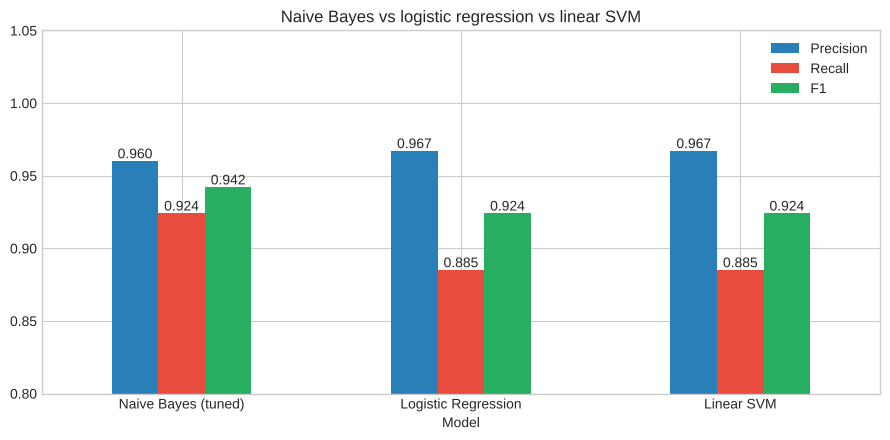

In [16]:
tfidf_params = dict(ngram_range=(1, 2), sublinear_tf=False)
models = {
    "Naive Bayes (tuned)": best,
    "Logistic Regression": GridSearchCV(make_pipeline(TfidfVectorizer(**tfidf_params), LogisticRegression(max_iter=3000)),
                                        {"logisticregression__C": [1, 10, 100]}, cv=cv, scoring="f1", n_jobs=-1),
    "Linear SVM": GridSearchCV(make_pipeline(TfidfVectorizer(**tfidf_params), LinearSVC()),
                               {"linearsvc__C": [0.1, 1, 10]}, cv=cv, scoring="f1", n_jobs=-1),
}
rows = []
for name, model in models.items():
    est = model if name.startswith("Naive") else model.fit(X_train, y_train).best_estimator_
    t0 = time.time(); est.fit(X_train, y_train); fit_time = time.time() - t0      # time ONE final fit
    p = est.predict(X_test)
    rows.append({"Model": name, "Precision": precision_score(y_test, p), "Recall": recall_score(y_test, p),
                 "F1": f1_score(y_test, p), "Accuracy": accuracy_score(y_test, p), "Fit time (s)": fit_time})
final = pd.DataFrame(rows).set_index("Model").round(3)
display(final)

ax = final[["Precision", "Recall", "F1"]].plot(kind="bar", figsize=(9, 4.5), color=["#2980b9", "#e74c3c", "#27ae60"], rot=0)
ax.set_ylim(0.8, 1.05); ax.set_title("Naive Bayes vs logistic regression vs linear SVM")
for c in ax.containers:
    ax.bar_label(c, fmt="%.3f")
plt.tight_layout()
plt.savefig("images/09_model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

### 📝 Observations (comparison)
| Model (TF-IDF 1 to 2-grams, tuned) | Precision | Recall | F1 | Accuracy |
|---|---|---|---|---|
| **Naive Bayes** | 0.960 | **0.924** | **0.942** | **0.985** |
| Linear SVM | 0.967 | 0.885 | 0.924 | 0.982 |
| Logistic Regression | 0.967 | 0.885 | 0.924 | 0.982 |

- Naive Bayes catches **5 more spam messages** than the other two (121 vs 116) at the cost of **one more false alarm** (5 vs 4): a small edge, on a test set of only 131 spam messages
- It is also the **fastest to train** (it only counts words; in the run above 0.13 s vs 0.22 s for the SVM and 1.1 s for logistic regression), which is why it is the classic first choice for text. Exact times depend on the machine

## 📱 Step 13: Try Your Own Messages

In [17]:
def check(message, threshold=0.7):
    p = best.predict_proba([message])[0, 1]
    verdict = "🚫 SPAM" if p >= threshold else "✅ HAM"
    print(f"{verdict}   P(spam) = {p:.1%}   |   {message}")

samples = [
    "WINNER!! You have won a free prize, call now to claim your reward",
    "Hey, are we still meeting for lunch tomorrow?",
    "URGENT! Your mobile number has won £2000. Txt CLAIM to 80086 now",
    "Ok see you at 5",
    "Congratulations! Free entry to our weekly draw, reply WIN to 87121",
    "Can you send me the notes from class? Thanks",
]
for s in samples:
    check(s)

🚫 SPAM   P(spam) = 100.0%   |   WINNER!! You have won a free prize, call now to claim your reward
✅ HAM   P(spam) = 0.0%   |   Hey, are we still meeting for lunch tomorrow?
🚫 SPAM   P(spam) = 100.0%   |   URGENT! Your mobile number has won £2000. Txt CLAIM to 80086 now
✅ HAM   P(spam) = 0.5%   |   Ok see you at 5
🚫 SPAM   P(spam) = 100.0%   |   Congratulations! Free entry to our weekly draw, reply WIN to 87121
✅ HAM   P(spam) = 0.2%   |   Can you send me the notes from class? Thanks


## ✅ Conclusion
- Naive Bayes classifies a message by **counting words**: P(spam) times the product of P(word | spam), computed in log space. We verified this **by hand against scikit-learn**
- Data hygiene matters: **403 duplicate messages** would have leaked into the test set, so they were removed *before* splitting
- With the 13% spam imbalance, **accuracy is misleading**; the spam-class **precision, recall and F1** tell the real story
- The default **TF-IDF + alpha = 1** model missed 38% of spam (recall 0.618). Tuning **`alpha` to the scale of the features** (0.01) and adding word pairs lifted F1 from **0.764 to 0.942**
- The tuned model reaches **accuracy 0.986, precision 0.960, recall 0.924, ROC-AUC 0.991** (5 false alarms and 10 missed spam in 1,034 test messages), and the threshold lets you trade recall for precision
- It is fast, needs no iterative training and is **fully interpretable**, but it cannot understand context, so personal-looking spam still slips through

## 🎤 Interview Questions: Short Answers
1. **What is Bayes' theorem and how does Naive Bayes use it?** P(class | features) = P(features | class) · P(class) / P(features). Naive Bayes picks the class with the largest numerator: the class prior times the likelihood of the observed features.
2. **Why is it called "naive"?** It assumes all features (words) are **conditionally independent** given the class, so the joint likelihood becomes a simple product of per-word probabilities. This is rarely true in language, yet the classification is often still accurate.
3. **What is Laplace (additive) smoothing and why is it needed?** Adding `alpha` to every word count avoids zero probabilities for words never seen in a class (which would wipe out the whole product). Larger `alpha` means more smoothing; it must be tuned (here 0.01 to 0.05 for TF-IDF).
4. **Multinomial vs Bernoulli vs Gaussian Naive Bayes?** Multinomial: word counts / frequencies (text). Bernoulli: binary presence/absence of words. Gaussian: continuous features assumed normally distributed within each class. Complement NB is a variant suited to imbalanced text.
5. **Bag of Words vs TF-IDF?** BoW counts words; TF-IDF down-weights words common to many documents and normalises length. They change the feature scale, which is why the best `alpha` differs (BoW is fine anywhere from 0.1 to 1, TF-IDF needs ≈ 0.01 to 0.05).
6. **Why do we use log probabilities?** Multiplying hundreds of small probabilities underflows to 0; summing their logs is stable and gives the same ranking of classes.
7. **Why is Naive Bayes good for text?** Very high-dimensional sparse features, fast to train (just counting), works with small datasets, robust, and its predictions are interpretable.
8. **Why is accuracy a bad metric for spam detection?** With 12.6% spam, always predicting "ham" is 87.4% accurate. Use precision, recall, F1 and PR-AUC, and choose the threshold according to the cost of false positives vs false negatives.
9. **What is data leakage and where did it show up here?** Information from the test set leaking into training. Exact duplicate messages (403) appeared in both splits (129 of 1,115 test messages), so we de-duplicated first.
10. **What are the limitations of Naive Bayes?** The independence assumption ignores word order and context, probabilities are often poorly calibrated (overconfident), and it cannot learn feature interactions, so stronger models (linear SVM, boosting, transformers) can outperform it.
11. **How would you improve this spam filter?** Add engineered features (digit count, URL / phone-number patterns, length, capitals), use character n-grams, combine with a linear model, and retrain regularly because spam keeps changing.